# Radar-gauge merging, verified at gauges left out: KTLX and KDAX

**Question.** The radar-only hourly totals of radarwow-verify notebook 05 are within a few per cent of the
gauge-corrected reference on KTLX but still ~20 % low on KDAX. How much do rain gauges improve them, and which
merging method is best?

**Methods** (`radarwow.merging`), the set compared by Goudenhoofdt & Delobbe (2009, HESS,
doi:10.5194/hess-13-195-2009): mean field bias (MFB), Brandes (1975) spatially varying factors, ordinary kriging of
the gauges alone, conditional merging (Sinclair & Pegram 2005) and kriging with the radar as external drift (KED).

**Verification.** Leave-one-out: each gauge in turn is removed, the field is merged from the others, and the
estimate at the removed gauge is compared with what it measured. The MRMS gauge-corrected product cannot be the
reference here: it was built with these same gauges.

**Data.** Radar: `radarwow.pipeline.hourly_totals` (the chain of verify notebooks 01-05). Gauges: hourly HADS
reports from the Iowa Environmental Mesonet archive (free). HADS data come with little quality control, so the
results are shown twice: with basic checks only, and with an extra gross-error check (see section 1).

In [1]:
# Colab: uncomment to install
!pip install -q cfgrib eccodes pysteps opencv-python-headless rasterio "git+https://github.com/manmeet3591/radarwow-pipeline" "git+https://github.com/manmeet3591/radarwow-merging"

zsh:1: command not found: pip


In [2]:
import os
import warnings

warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from radarwow.merging import METHODS, leave_one_out, merge, radar_at
from radarwow.pipeline import hourly_totals
from radarwow.verify import basic_qc, fetch_hads, fetch_mrms, gross_error_qc

FIG = "../docs/figures"
CACHE = os.path.expanduser("~/.cache/radarwow")
CASES = {"KTLX": dict(network="OK_DCP", start="2022-05-05 07:00", end="2022-05-05 11:00", n_tilts=1, blockage=False),
         "KDAX": dict(network="CA_DCP", start="2021-10-24 12:00", end="2021-10-24 16:00", n_tilts=3, blockage=True)}
MAX_KM = 145  # keep gauges a 3 x 3 window inside the 150 km radar disk

## 1. Radar totals and gauges

In [3]:
data = {}
qc_rows = []
for site, c in CASES.items():
    rad = hourly_totals(site, c["start"], c["end"], n_tilts=c["n_tilts"], blockage=c["blockage"])
    lat0, lon0 = rad.attrs["radar_lat"], rad.attrs["radar_lon"]
    g = fetch_hads(c["network"], lat0, lon0, MAX_KM, c["start"], c["end"], f"{CACHE}/gauges")
    g["gx"] = (g["lon"] - lon0) * 111.2 * np.cos(np.deg2rad(lat0))
    g["gy"] = (g["lat"] - lat0) * 111.2
    x, y = rad["x"].values, rad["y"].values
    g["radar_mm"] = np.nan
    for t, idx in g.groupby("time").groups.items():
        field = rad["RAIN"].sel(time=t).values
        g.loc[idx, "radar_mm"] = radar_at(field, x, y, g.loc[idx, "gx"].values, g.loc[idx, "gy"].values)
    g = gross_error_qc(basic_qc(g, radar_col="radar_mm"), radar_col="radar_mm")
    for reason, n in g["qc"].value_counts().items():
        qc_rows.append(dict(site=site, check=reason, gauge_hours=n))
    basic_ok = ~g["qc"].isin(["impossible value", "gauge dry under radar rain", "gauge rain with no radar echo", "no radar value"])
    data[site] = (rad, {"basic QC": g[basic_ok].reset_index(drop=True), "basic + gross-error QC": g[g["qc"] == "ok"].reset_index(drop=True)})
display(Markdown("**Gauge quality control** (gauge-hours). The gross-error check flags gauge-hours that differ from the radar by "
                 "more than 5 mm and a factor of 3 after scaling the radar by the hour's median gauge/radar ratio, and drops "
                 "stations flagged twice. It uses the radar, so it leans the comparison towards the radar; both versions "
                 "are shown below.\n\n" + pd.DataFrame(qc_rows).pivot_table(index="check", columns="site", values="gauge_hours", fill_value=0).to_markdown()))

**Gauge quality control** (gauge-hours). The gross-error check flags gauge-hours that differ from the radar by more than 5 mm and a factor of 3 after scaling the radar by the hour's median gauge/radar ratio, and drops stations flagged twice. It uses the radar, so it leans the comparison towards the radar; both versions are shown below.

| check                              |   KDAX |   KTLX |
|:-----------------------------------|-------:|-------:|
| gauge dry under radar rain         |     37 |     14 |
| gauge rain with no radar echo      |      2 |      0 |
| gross error vs bias-scaled radar   |     70 |      5 |
| impossible value                   |     12 |      0 |
| no radar value                     |     10 |     27 |
| ok                                 |    702 |    297 |
| station with repeated gross errors |     17 |      1 |

## 2. Leave-one-out at the gauges

In [4]:
loo = []
for site, (rad, gsets) in data.items():
  x, y = rad["x"].values, rad["y"].values
  for qc_name, g in gsets.items():
    for t, gt in g.groupby("time"):
        field = rad["RAIN"].sel(time=t).values
        for m in METHODS:
            est = leave_one_out(m, field, x, y, gt["gx"].values, gt["gy"].values, gt["gauge_mm"].values)
            loo.append(pd.DataFrame(dict(site=site, qc=qc_name, time=t, method=m, station=gt["station"].values, gauge=gt["gauge_mm"].values, est=est)))
        # MRMS radar-only at the gauges: a fair peer (no gauges in it); the gauge-corrected product is not independent
        for prod, label in [("radar_only", "MRMS radar-only"), ("gauge_corrected", "MRMS gauge-corrected (uses these gauges)")]:
            mr = fetch_mrms(prod, pd.Timestamp(t) + pd.Timedelta(hours=1), f"{CACHE}/mrms")
            v = mr.sel(latitude=gt["lat"].to_xarray(), longitude=gt["lon"].to_xarray(), method="nearest").values
            loo.append(pd.DataFrame(dict(site=site, qc=qc_name, time=t, method=label, station=gt["station"].values, gauge=gt["gauge_mm"].values, est=v)))
loo = pd.concat(loo, ignore_index=True)


def summary(d):
    d = d.dropna(subset=["est"])
    e, g = d["est"].values, d["gauge"].values
    return pd.Series(dict(n=len(d), bias=e.sum() / g.sum(), MAE=np.mean(np.abs(e - g)), RMSE=np.sqrt(np.mean((e - g) ** 2)),
                          corr=np.corrcoef(e, g)[0, 1]))


order = list(METHODS) + ["MRMS radar-only", "MRMS gauge-corrected (uses these gauges)"]
for site in CASES:
  for qc_name in ["basic QC", "basic + gross-error QC"]:
    s = loo[(loo.site == site) & (loo.qc == qc_name)].groupby("method").apply(summary).loc[order]
    s["MAE vs radar only"] = (s["MAE"] / s.loc["radar only", "MAE"] - 1).map(lambda v: f"{v:+.0%}")
    display(Markdown(f"**{site}, {qc_name}**: all gauge-hours (bias = sum of estimates / sum of gauges; MAE, RMSE in mm)\n\n"
                     + s.round({"bias": 2, "MAE": 2, "RMSE": 2, "corr": 2}).to_markdown()))

**KTLX, basic QC**: all gauge-hours (bias = sum of estimates / sum of gauges; MAE, RMSE in mm)

| method                                   |   n |   bias |   MAE |   RMSE |   corr | MAE vs radar only   |
|:-----------------------------------------|----:|-------:|------:|-------:|-------:|:--------------------|
| radar only                               | 303 |   1.08 |  1.06 |   3.24 |   0.6  | +0%                 |
| MFB                                      | 303 |   1    |  1.1  |   3.31 |   0.6  | +4%                 |
| Brandes                                  | 303 |   1.31 |  1.62 |   5.84 |   0.29 | +53%                |
| kriging (gauges only)                    | 303 |   0.96 |  1.51 |   4.12 |   0.31 | +42%                |
| conditional merging                      | 303 |   1    |  1.24 |   3.82 |   0.49 | +17%                |
| KED                                      | 303 |   1.02 |  1.37 |   3.95 |   0.47 | +30%                |
| MRMS radar-only                          | 303 |   1.22 |  1.25 |   3.4  |   0.58 | +18%                |
| MRMS gauge-corrected (uses these gauges) | 303 |   0.95 |  0.75 |   3.16 |   0.63 | -29%                |

**KTLX, basic + gross-error QC**: all gauge-hours (bias = sum of estimates / sum of gauges; MAE, RMSE in mm)

| method                                   |   n |   bias |   MAE |   RMSE |   corr | MAE vs radar only   |
|:-----------------------------------------|----:|-------:|------:|-------:|-------:|:--------------------|
| radar only                               | 297 |   1.23 |  0.74 |   1.12 |   0.92 | +0%                 |
| MFB                                      | 297 |   1    |  0.68 |   1.08 |   0.92 | -9%                 |
| Brandes                                  | 297 |   1.13 |  0.73 |   1.29 |   0.88 | -2%                 |
| kriging (gauges only)                    | 297 |   0.94 |  0.99 |   2.19 |   0.59 | +33%                |
| conditional merging                      | 297 |   0.99 |  0.6  |   1.07 |   0.92 | -19%                |
| KED                                      | 297 |   1.01 |  0.66 |   1.24 |   0.9  | -11%                |
| MRMS radar-only                          | 297 |   1.39 |  0.92 |   1.39 |   0.91 | +23%                |
| MRMS gauge-corrected (uses these gauges) | 297 |   1.06 |  0.42 |   0.82 |   0.96 | -43%                |

**KDAX, basic QC**: all gauge-hours (bias = sum of estimates / sum of gauges; MAE, RMSE in mm)

| method                                   |   n |   bias |   MAE |   RMSE |   corr | MAE vs radar only   |
|:-----------------------------------------|----:|-------:|------:|-------:|-------:|:--------------------|
| radar only                               | 789 |   0.51 |  4.1  |   6.75 |   0.44 | +0%                 |
| MFB                                      | 789 |   1    |  4.09 |   7.07 |   0.43 | -0%                 |
| Brandes                                  | 789 |   1.11 |  3.07 |   6.86 |   0.52 | -25%                |
| kriging (gauges only)                    | 789 |   1    |  2.7  |   5.8  |   0.55 | -34%                |
| conditional merging                      | 789 |   1    |  2.71 |   5.81 |   0.56 | -34%                |
| KED                                      | 789 |   1    |  2.7  |   5.82 |   0.55 | -34%                |
| MRMS radar-only                          | 789 |   0.41 |  4.31 |   7.01 |   0.48 | +5%                 |
| MRMS gauge-corrected (uses these gauges) | 789 |   0.82 |  2.31 |   5.24 |   0.64 | -44%                |

**KDAX, basic + gross-error QC**: all gauge-hours (bias = sum of estimates / sum of gauges; MAE, RMSE in mm)

| method                                   |   n |   bias |   MAE |   RMSE |   corr | MAE vs radar only   |
|:-----------------------------------------|----:|-------:|------:|-------:|-------:|:--------------------|
| radar only                               | 702 |   0.46 |  3.62 |   5.23 |   0.72 | +0%                 |
| MFB                                      | 702 |   1    |  3.09 |   4.66 |   0.71 | -15%                |
| Brandes                                  | 702 |   1.11 |  2.28 |   3.88 |   0.82 | -37%                |
| kriging (gauges only)                    | 702 |   1.02 |  1.85 |   2.78 |   0.87 | -49%                |
| conditional merging                      | 702 |   1.02 |  1.8  |   2.7  |   0.88 | -50%                |
| KED                                      | 702 |   1.01 |  1.77 |   2.64 |   0.88 | -51%                |
| MRMS radar-only                          | 702 |   0.4  |  4.1  |   5.77 |   0.7  | +13%                |
| MRMS gauge-corrected (uses these gauges) | 702 |   0.84 |  1.89 |   3.15 |   0.86 | -48%                |

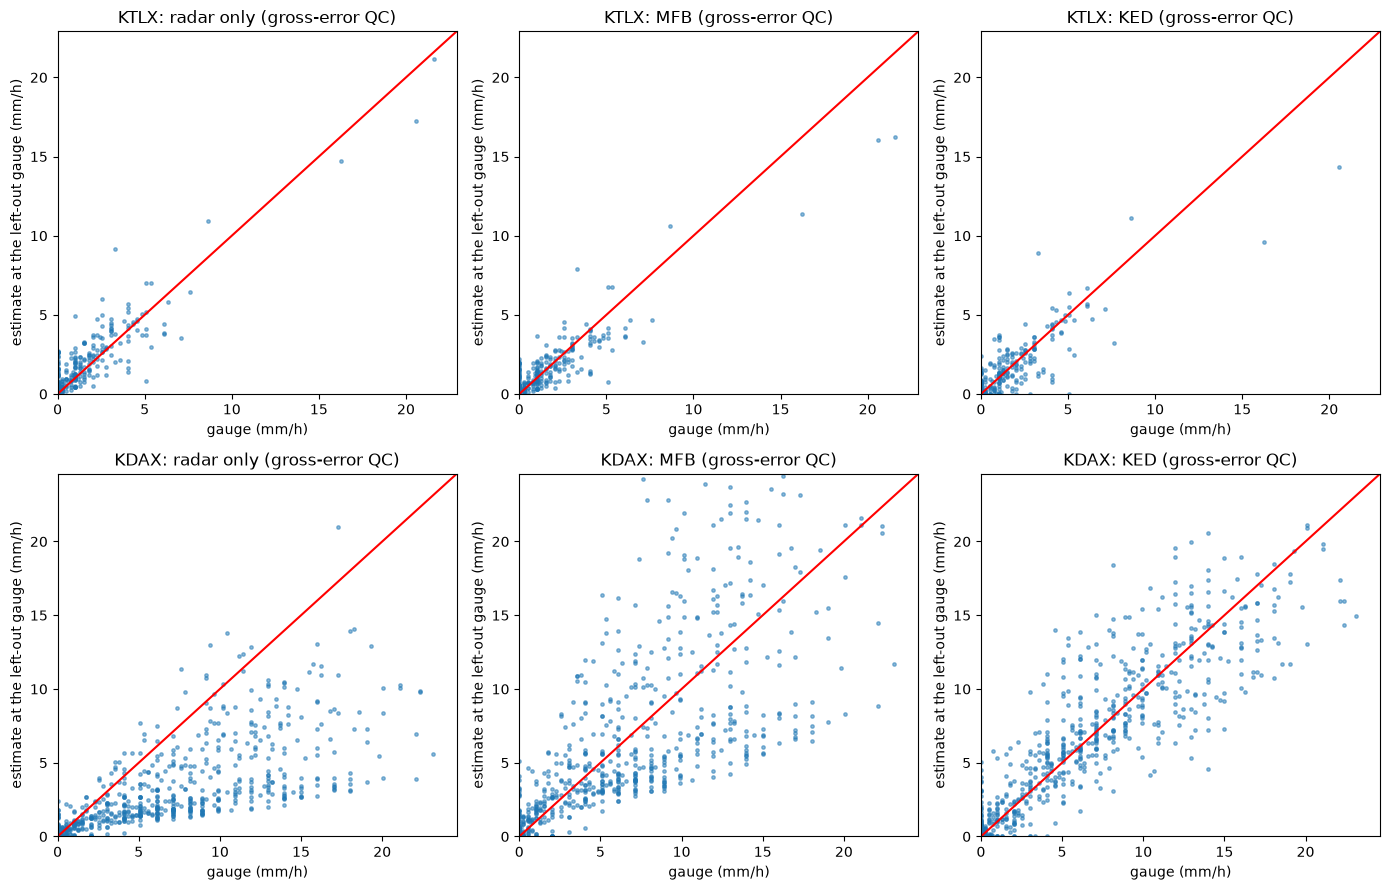

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(14, 9))
for row, site in zip(axes, CASES):
    d = loo[(loo.site == site) & (loo.qc == "basic + gross-error QC")]
    lim = np.nanpercentile(d["gauge"], 99.5) * 1.1
    for ax, m in zip(row, ["radar only", "MFB", "KED"]):
        dm = d[d.method == m]
        ax.scatter(dm["gauge"], dm["est"], s=6, alpha=0.5)
        ax.plot([0, lim], [0, lim], "r")
        ax.set(xlim=(0, lim), ylim=(0, lim), title=f"{site}: {m} (gross-error QC)", xlabel="gauge (mm/h)", ylabel="estimate at the left-out gauge (mm/h)")
fig.tight_layout()
fig.savefig(f"{FIG}/01_loo_scatter.png", dpi=100)
plt.show()

## 3. Merged maps

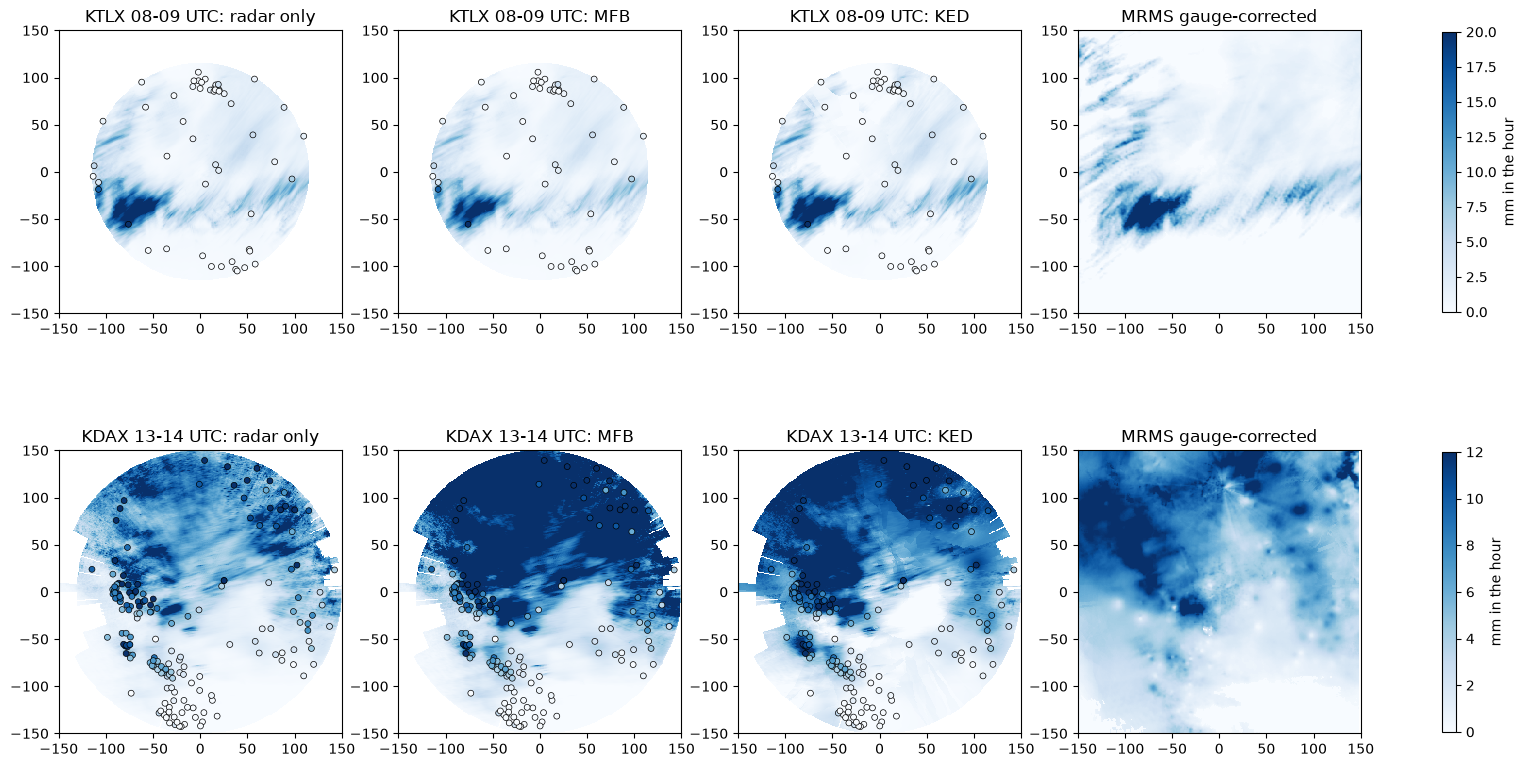

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(21, 10))
for row, (site, hour) in zip(axes, [("KTLX", "2022-05-05 08:00"), ("KDAX", "2021-10-24 13:00")]):
    rad, gsets = data[site]
    g = gsets["basic + gross-error QC"]
    t = pd.Timestamp(hour)
    x, y = rad["x"].values, rad["y"].values
    field = rad["RAIN"].sel(time=t).values
    gt = g[g.time == t]
    vmax = 20 if site == "KTLX" else 12
    panels = [("radar only", field), ("MFB", merge("MFB", field, x, y, gt.gx.values, gt.gy.values, gt.gauge_mm.values)),
              ("KED", merge("KED", field, x, y, gt.gx.values, gt.gy.values, gt.gauge_mm.values))]
    for ax, (title, f) in zip(row[:3], panels):
        p = ax.pcolormesh(x, y, np.ma.masked_invalid(f), cmap="Blues", vmin=0, vmax=vmax, shading="auto")
        ax.scatter(gt.gx, gt.gy, c=gt.gauge_mm, cmap="Blues", vmin=0, vmax=vmax, s=18, edgecolors="k", linewidths=0.5)
        ax.set(title=f"{site} {t:%H}-{t.hour + 1:02d} UTC: {title}", aspect=1)
    ref = fetch_mrms("gauge_corrected", t + pd.Timedelta(hours=1), f"{CACHE}/mrms")
    lat0, lon0 = rad.attrs["radar_lat"], rad.attrs["radar_lon"]
    box = ref.sel(latitude=slice(lat0 + 1.36, lat0 - 1.36), longitude=slice(lon0 - 1.7, lon0 + 1.7))
    bx = (box.longitude - lon0) * 111.2 * np.cos(np.deg2rad(lat0))
    by = (box.latitude - lat0) * 111.2
    row[3].pcolormesh(bx, by, np.ma.masked_invalid(box.values), cmap="Blues", vmin=0, vmax=vmax, shading="auto")
    row[3].set(title="MRMS gauge-corrected", aspect=1, xlim=(-150, 150), ylim=(-150, 150))
    fig.colorbar(p, ax=row, label="mm in the hour", shrink=0.8)
fig.savefig(f"{FIG}/02_merged_maps.png", dpi=85, bbox_inches="tight")
plt.show()

## Takeaways
- **Gauge quality control decides the outcome on KTLX.** With basic checks, every merging method is worse than the
  radar alone at the left-out gauges. Six bad gauge-hours (of 303) cause that: one gauge reporting 46 mm under
  4 mm of radar and MRMS rain, one reporting an hour late, and gauges stuck at 0 under 9-13 mm. Without them the
  radar-gauge correlation goes from 0.60 to 0.92, and conditional merging cuts the error by 19 % (KED 11 %, MFB 9 %).
- **KTLX needs the radar.** Kriging the gauges alone is 33 % worse than the radar: convective rain with about one
  gauge per 700 km^2. This is the summer result of Goudenhoofdt & Delobbe 2009.
- **KDAX gains a lot from gauges, with either QC:** KED, conditional merging and kriging cut the error by 34 %
  (basic QC) or about 50 % (with the gross-error check, which removes 11 % of gauge-hours, so the 34 % is the safer
  number). Bias goes from 0.46-0.51 to 1.0. Kriging the gauges alone does as well as KED: 230 gauges in steady rain
  carry most of the information (the paper's winter result). Mean field bias alone gains little (0 to 15 %): it
  doubles the whole field, overshooting in the lightly raining south.
- **Against MRMS.** With the gross-error check, KED's leave-one-out error on KDAX (1.77 mm) is slightly lower than
  MRMS gauge-corrected's (1.89 mm), although MRMS uses these same gauges in its analysis. MRMS radar-only, which
  uses no gauges, is worse than our radar-only on both cases.
- **Recommendation:** conditional merging or KED, always behind gauge QC; MFB only where gauges are very sparse.
- **Limits:** two cases, four hours each; leave-one-out at gauges is the only independent check here (no separate
  gauge network); the gross-error check uses the radar, which favours the radar slightly.